Net(
  (fc1): Linear(in_features=1, out_features=16, bias=True)
  (act1): Tanh()
  (fc2): Linear(in_features=16, out_features=16, bias=True)
  (act2): Tanh()
  (fc3): Linear(in_features=16, out_features=1, bias=True)
)
[Parameter containing:
tensor([[ 0.3066],
        [-0.9229],
        [-0.8026],
        [ 0.1302],
        [ 0.5766],
        [ 0.2646],
        [ 0.2618],
        [ 0.2404],
        [-0.2466],
        [-0.2804],
        [ 0.1131],
        [ 0.0394],
        [ 0.9090],
        [ 0.5970],
        [ 0.6365],
        [-0.6608]], requires_grad=True), Parameter containing:
tensor([ 0.1325,  0.8033, -0.5506, -0.3546,  0.5854,  0.9352, -0.8683, -0.1927,
         0.8159, -0.0212,  0.1570, -0.6998,  0.8107, -0.0864, -0.9675,  0.2983],
       requires_grad=True), Parameter containing:
tensor([[ 1.2486e-01, -1.1504e-01,  2.1264e-01, -2.8161e-02, -1.1712e-05,
         -2.1211e-01,  1.1329e-01,  7.5698e-02, -1.9750e-01, -4.9676e-02,
         -1.4615e-01,  1.0684e-01, -2.1172e-01,  3.

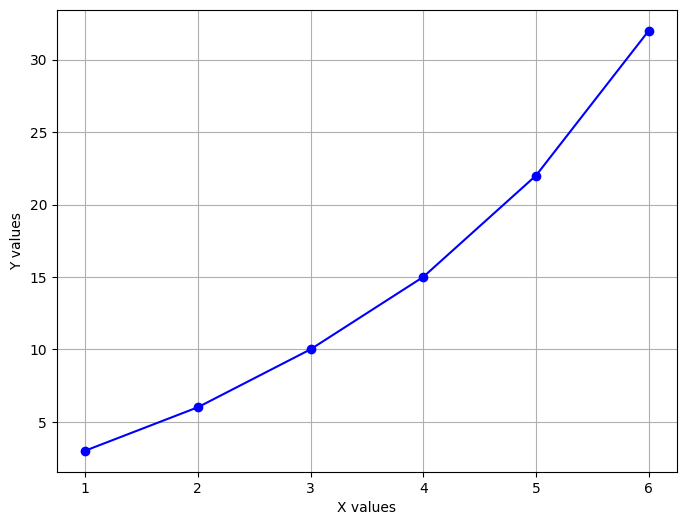

In [46]:
### Training with fancier version ###

import torch
import torch.nn as nn
import torch.nn.functional as F

import torch.optim as optim
import matplotlib.pyplot as plt

class Net(nn.Module): ## nn.Module class is used
    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(1, 16, bias=True)
        self.act1 = nn.Tanh()

        self.fc2 = nn.Linear(16, 16, bias=True)
        self.act2 = nn.Tanh()

        self.fc3 = nn.Linear(16, 1, bias=True)

    def forward(self, x):
        x = self.act1(self.fc1(x))
        x = self.act2(self.fc2(x))
        x = self.fc3(x)  # No output activation
        return x

net = Net()

print(net)
print(list(net.parameters())) # parameters are randomized


#def criterion(out, label):
#    return (label - out)**2
criterion = nn.MSELoss()


# optimizer = optim.SGD(net.parameters(), lr=0.1)
optimizer = optim.Adam(net.parameters(), lr=0.01)


data = [(1.0,3.0), (2.0,6.0), (3.0,10.0), (4.0,15.0), (5.0,22.0), (6.0,32.0)]

# Split data into x and y
x_values, y_values = zip(*data)

# Plotting
plt.figure(figsize=(8, 6))
plt.plot(x_values, y_values, marker='o', linestyle='-', color='b')
plt.xlabel('X values')
plt.ylabel('Y values')
plt.grid(True)
plt.show()

In [47]:
for epoch in range(1000): 
    for i, current_data in enumerate(data):
        X, Y = current_data
        X, Y = torch.FloatTensor([X]), torch.FloatTensor([Y])
        optimizer.zero_grad()   
        outputs = net(X)
        loss = criterion(outputs, Y)
        loss.backward()
        optimizer.step()    ## This line is equivalent to "W = W - lr* W.grad"
    print("Epoch {} - loss: {}".format(epoch, loss))


### Test the trained network ###            
for i, current_data in enumerate(data):
    X, Y = current_data
    X, Y = torch.FloatTensor([X]), torch.FloatTensor([Y])  
    out = net(torch.FloatTensor(X))  
    print("when x = {}, y = {}".format(X, out))
    

Epoch 0 - loss: 928.57861328125
Epoch 1 - loss: 858.5050659179688
Epoch 2 - loss: 802.590087890625
Epoch 3 - loss: 754.3414306640625
Epoch 4 - loss: 709.4274291992188
Epoch 5 - loss: 667.6375732421875
Epoch 6 - loss: 629.424072265625
Epoch 7 - loss: 594.7835083007812
Epoch 8 - loss: 563.53173828125
Epoch 9 - loss: 535.4067993164062
Epoch 10 - loss: 510.1085510253906
Epoch 11 - loss: 487.3191223144531
Epoch 12 - loss: 466.70892333984375
Epoch 13 - loss: 447.9522705078125
Epoch 14 - loss: 430.67742919921875
Epoch 15 - loss: 413.66021728515625
Epoch 16 - loss: 394.3923645019531
Epoch 17 - loss: 374.682373046875
Epoch 18 - loss: 356.69561767578125
Epoch 19 - loss: 340.4415283203125
Epoch 20 - loss: 325.405029296875
Epoch 21 - loss: 310.7611083984375
Epoch 22 - loss: 296.2897644042969
Epoch 23 - loss: 282.58563232421875
Epoch 24 - loss: 269.70654296875
Epoch 25 - loss: 257.29998779296875
Epoch 26 - loss: 245.40037536621094
Epoch 27 - loss: 234.19195556640625
Epoch 28 - loss: 223.56599426269

In [ ]:
X

In [ ]:
for epoch in range(20):
    print(epoch)

In [ ]:
W = torch.tensor([1.0], requires_grad=True)
W = W*2
label = 1.0
loss = W*5 - label 
loss.backward()
W.grad